In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib.patches as mpatches



In [2]:
folder = Path("../data/groundwater/DiverCSV")

nest_depth = 0.6                                                                   # m
well_offsets = {"A1": -1.657, "A2": 1.602, "B1": 0.888, "B2": 1.602, "B3": 0.043}  # cmH2O
baro_offset = -0.829                                                               # cmH2O

well_z = {"A1": 3.945 - 0.490, "A2": 4.076 - 0.612, "B1": 2.820, "B2": 2.752, "B3": 2.252}         # m
well_b = {"A1": 0.490, "A2": 0.612, "B1": 0.400, "B2": 0.442, "B3": 0.334}         # m
well_toc = {k: well_z[k] + well_b[k] for k in well_z}                              # m
CL = 2.044 - 0.097 - 0.100                                                         # m

well_x = {'B1': 36.5, 'B2': 46, 'B3': 55}
wellA_x = {'A1': 23.5}

def read_diver(file):
    df = pd.read_csv(file, skiprows=51, sep=",", encoding="cp1252", usecols=[0, 1])[:-1]
    df["Date/time"] = pd.to_datetime(df["Date/time"])
    df["Pressure[cmH2O]"] = pd.to_numeric(df["Pressure[cmH2O]"], errors="coerce")
    return df.dropna().sort_values("Date/time")

baro = read_diver(next(folder.glob("Baro*.CSV")))

tranB = pd.read_csv('../data/groundwater/well_transect_profile.csv')
tranB['z'] = tranB[['Monday', 'Tuesday', 'Wednesday']].mean(axis=1)

tranA = pd.read_csv('../data/groundwater/wellA_transect_profile.csv')
tranA['z'] = tranA[['Monday', 'Tuesday', 'Wednesday']].mean(axis=1)

files = [f for f in folder.glob("*.CSV") if f.stem.split("_")[0] in well_offsets]
all_divers = pd.concat([read_diver(f).assign(Diver=f.stem.split("_")[0]) for f in files], ignore_index=True)


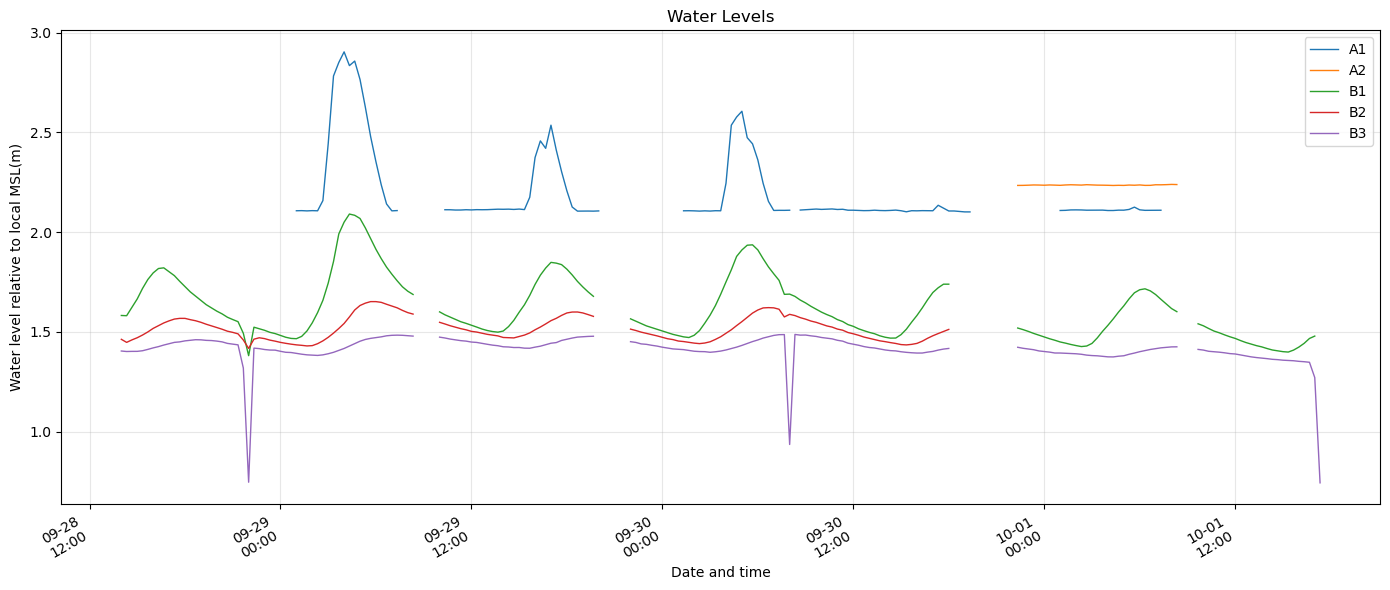

In [3]:
baro["Pressure[mH2O]"] = (baro["Pressure[cmH2O]"] - baro_offset) / 100             # m

all_divers["Pressure[mH2O]"] = (all_divers["Pressure[cmH2O]"] - all_divers["Diver"].map(well_offsets)) / 100
baro_at_diver_time = np.interp(all_divers["Date/time"].astype("int64"), baro["Date/time"].astype("int64"), baro["Pressure[mH2O]"])

all_divers["WC"] = all_divers["Pressure[mH2O]"] - baro_at_diver_time
all_divers["WL"] = all_divers["Diver"].map(well_toc) - CL + all_divers["WC"]

fig, ax = plt.subplots(figsize=(14, 6))

for name, df in all_divers.groupby("Diver"):
    s = df.set_index("Date/time")["WL"].resample("20min").mean()
    ax.plot(s.index.to_numpy(), s.to_numpy(), label=name, linewidth=1)

ax.set_xlabel("Date and time")
ax.set_ylabel("Water level relative to local MSL(m)")
ax.set_title("Water Levels")
ax.legend()
ax.grid(alpha=0.3)

ax.xaxis.set_major_locator(mdates.AutoDateLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d\n%H:%M"))

fig.autofmt_xdate()
fig.tight_layout()

NameError: name 'NEST' is not defined

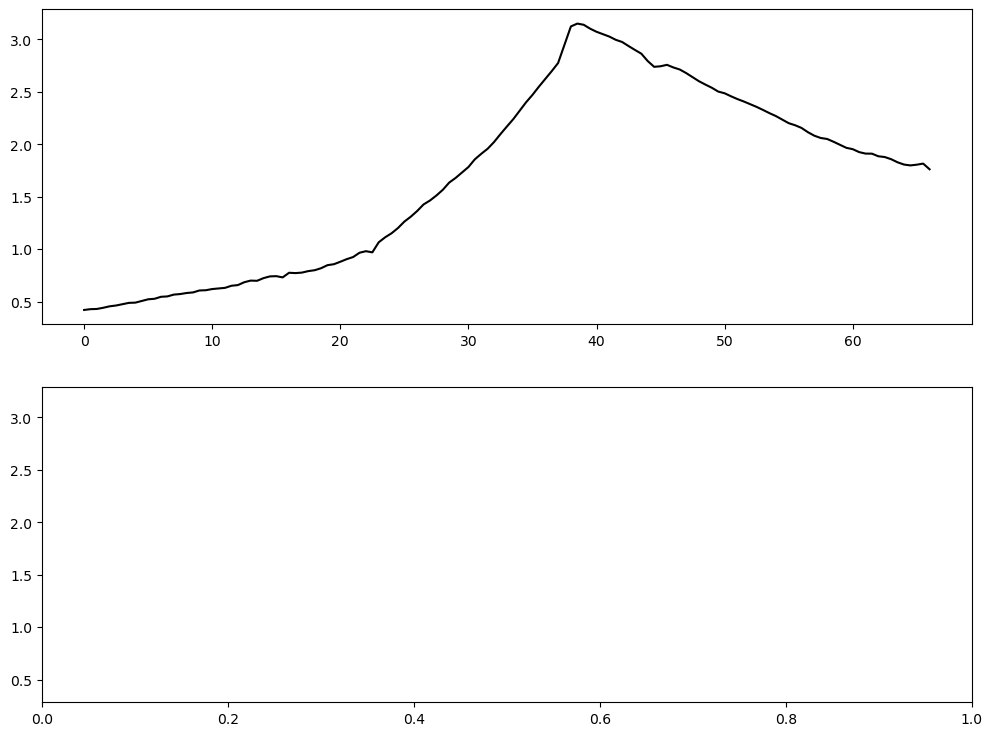

In [4]:
start = pd.Timestamp('2026-09-28 18:55')
end = pd.Timestamp('2026-10-01 09:00')

wl = all_divers[all_divers['Date/time'].between(start, end) & (all_divers['WC'] > 0.03)]

box_style = dict(whis=(5, 95), showfliers=False, showmeans=True, patch_artist=True,
                 boxprops=dict(facecolor='#0a91a1'), medianprops=dict(color='k'),
                 meanprops=dict(marker='o', markerfacecolor='k', markeredgecolor='k', markersize=4))

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 9), sharey=True)

ax1.plot(tranB['distance_m'], tranB['z'], color='k', label='Beach profile')
ax1.fill_between(tranB['distance_m'], tranB['z'] - NEST, tranB['z'], color='#f8a953', alpha=0.6,
                 label=f'Nesting depth (0.6 m)')

for w, x in well_x.items():
    ax1.boxplot(wl.loc[wl['Diver'] == w, 'WL'], positions=[x], widths=1.5, **box_style)
    ax1.text(x, 0.98, w, ha="center", va="top", transform=ax1.get_xaxis_transform())

ax1.set_title('Wells B', fontweight='bold')
ax1.set_xlabel('Distance from shoreline [m]')
ax1.set_ylabel('Elevation [m]')
ax1.legend(loc='upper left')
ax1.grid(alpha=0.3)

ax2.plot(tranA['distance_m'], tranA['z'], color='k', label='Beach profile')
ax2.fill_between(tranA['distance_m'], tranA['z'] - NEST, tranA['z'], color='#f8a953', alpha=0.6,
                 label=f'Nesting depth (0.6 m)')

for w, x in wellA_x.items():
    ax2.boxplot(wl.loc[wl['Diver'] == w, 'WL'], positions=[x], widths=1.5, **box_style)
    ax2.text(x, 0.98, w, ha="center", va="top", transform=ax2.get_xaxis_transform())

ax2.set_title("Well A", fontweight="bold")
ax2.set_xlabel("Distance from shoreline [m]")
ax2.set_ylabel("Elevation [m]")
ax2.legend(loc='upper left')
ax2.grid(alpha=0.3)


plt.tight_layout()